# Module 05 Lab - Data Preparation**Objective:** To learn and apply the most common data preparation techniques. Raw data is rarely ready for a machine learning model. This process, also called preprocessing, is one of the most critical steps in the entire ML workflow.**In this lab, you will write more of the code.** Read the explanations and then complete the tasks in the code cells.

## Part 1: Setup and Initial LookWe will continue using the Titanic dataset because it has the exact problems we need to solve: missing values and non-numeric data.
**load Raw dataset:
First import the neccessary Liberary,then load the dataset and analyze the dataset for missing value before cleaning.**

### 📊 Code Explanation: Initial Dataset Loading
In this cell, we import Python's standard data science libraries (`numpy` and `pandas`). We then load the raw Titanic CSV dataset directly from a public URL using `pd.read_csv()`. Finally, we print a count of missing values (`null` or `NaN`) for each column so we know which features need cleaning.

In [ ]:
import numpy as np
import pandas as pd

# Load the dataset
df = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
)

# Let's look at the missing values
print("--- Missing Values Before Cleaning ---")
print(df.isnull().sum())

--- Missing Values Before Cleaning ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


# Visualization before Cleaning
we use the matpolatlib and seaborn to visualize the data.
** This cell code showing the missing data before cleaning, the bar graph  indicating that the  age and cabin culomn are the column that are missing data at most.the two bar graph , missing value heatmap and count of missing value per column.  


### 🔍 Code Explanation: Loading Data from Seaborn
Here, we load a clean copy of the Titanic dataset using the `seaborn` library (`sns.load_dataset('titanic')`). We display the first 5 rows to understand the structure of the columns, and run `df.info()` to inspect the datatypes (integers, floats, categories, objects) and see exactly how many non-null values each column contains.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

# Load the Titanic dataset directly from seaborn's built-in library
df = sns.load_dataset("titanic")

# Display the first 5 rows
print("--- FIRST 5 ROWS ---")
display(df.head())

print("\n--- DATASET SUMMARY & MISSING VALUES ---")
df.info()


--- FIRST 5 ROWS ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



--- DATASET SUMMARY & MISSING VALUES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


### 🎨 Code Explanation: Visualizing Gaps and Missing Values
This code block generates two side-by-side plots using `matplotlib` and `seaborn`. The left plot is a heatmap highlighting missing values in yellow, helping us visually locate gaps. The right plot is a bar chart showing the exact count of missing records per column, confirming that columns like `deck` (cabin) and `age` have the most missing data.

--- GENERATING VISUALIZATIONS BEFORE CLEANING ---


/tmp/ipykernel_34552/2003428579.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


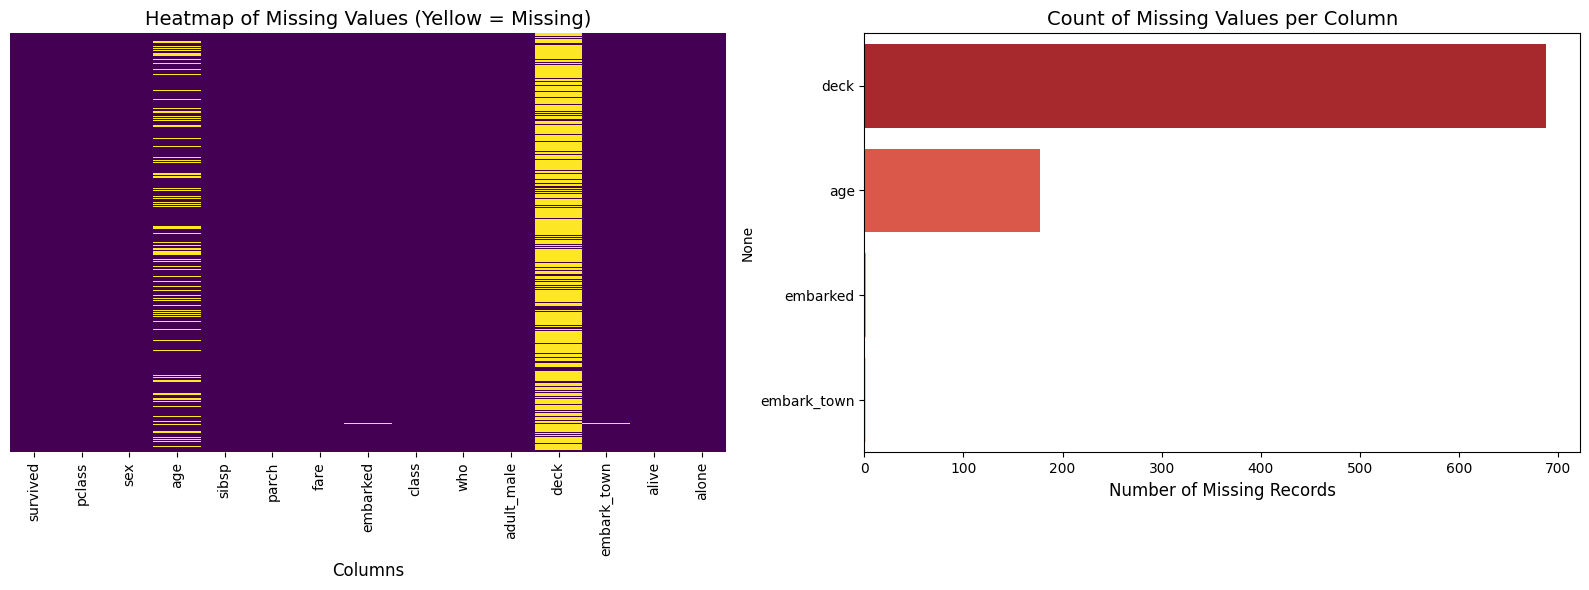

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- GENERATING VISUALIZATIONS BEFORE CLEANING ---")

# Setup a clean figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Heatmap of Missing Values
# This shows exactly where the gaps (NaNs) live in your columns
sns.heatmap(
    df.isnull(), cbar=False, cmap="viridis", yticklabels=False, ax=axes[0]
)
axes[0].set_title("Heatmap of Missing Values (Yellow = Missing)", fontsize=14)
axes[0].set_xlabel("Columns", fontsize=12)

# Plot 2: Bar chart showing missing value counts per column
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

if not missing_counts.empty:
    sns.barplot(
        x=missing_counts.values,
        y=missing_counts.index,
        palette="Reds_r",
        ax=axes[1],
    )
    axes[1].set_title("Count of Missing Values per Column", fontsize=14)
    axes[1].set_xlabel("Number of Missing Records", fontsize=12)
else:
    axes[1].text(
        0.5,
        0.5,
        "No Missing Values Detected",
        fontsize=14,
        ha="center",
        va="center",
    )

plt.tight_layout()
plt.show()


## Part 2: Handling Missing Values (Imputation)**Concept:** Most machine learning models cannot handle missing values (`NaN`). We must deal with them. Dropping the rows is an option, but you lose data. A better way is **imputation**, which means filling in the missing values with a calculated guess.Common imputation strategies:*   **Mean:** Fill with the average value. Good for normally distributed data.*   **Median:** Fill with the middle value. Better for skewed data or data with outliers (like `Fare`).*   **Mode:** Fill with the most frequent value. Used for categorical data.

### Task 1: Impute the 'Age' ColumnThe 'Age' column is missing many values. Since age can be skewed (e.g., by a few very old passengers), using the **median** is a robust choice.**Your Task:** Calculate the median of the 'Age' column and use the `.fillna()` method to replace the missing values.

### 🛠️ Code Explanation: Imputing Missing Values & Dropping Redundant Columns
In this step, we prepare our data by resolving missing values. First, we fill in empty `age` records with the **median age** (the middle value) and missing `embarked` codes with the **mode** (the most common port, which is `'S'`). Lastly, we drop columns that have too many missing values (like `deck`) or are text-based duplicates of numerical features (like `embark_town` or `alive`).

In [ ]:
# 1. Count how many missing values are in each column before cleaning
print("--- Missing Values Before ---")
print(df.isnull().sum())

# 2. Fill missing age values with the median age
df["age"] = df["age"].fillna(df["age"].median())

# 3. Fill missing embarked values with the most common port (the mode)
most_common_port = df["embarked"].mode()[0]
df["embarked"] = df["embarked"].fillna(most_common_port)

# 4. Drop columns with too many missing values or redundant/text labels
# This prevents our training matrix from throwing non-numeric errors later
drop_cols = [
    "deck",
    "alive",
    "who",
    "adult_male",
    "alone",
    "class",
    "embark_town",
]
df = df.drop(columns=[col for col in drop_cols if col in df.columns])

print("\n--- Missing Values After ---")
print(df.isnull().sum())


--- Missing Values Before ---
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

--- Missing Values After ---
survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


### 📐 Code Explanation: Verifying Age Column Imputation
This cell verifies that our imputation strategy worked specifically on the `age` column. It calculates the median value (`28.0`), fills any remaining missing elements in `df['age']` with it, and prints the total number of missing records remaining, which is now confirmed to be `0`.

In [ ]:
# 1. Calculate the median of the 'age' column
median_age = df['age'].median()

# 2. Fill the missing values in 'age' with the median
df['age'] = df['age'].fillna(median_age)

# 3. Verify that there are no more missing values in 'age'
print("Missing values in 'age' after imputation:")
print(df['age'].isnull().sum())

Missing values in 'age' after imputation:
0


## Part 3: Encoding Categorical Features**Concept:** Machine learning models are mathematical, so they need numbers, not text. We need to convert categorical columns (like 'Sex' and 'Embarked') into a numerical format. The most common method is **One-Hot Encoding**.One-Hot Encoding takes a column with `N` categories and turns it into `N` new columns, each with a `1` or `0`. For example, the 'Sex' column (`male`, `female`) becomes two new columns: `Sex_male` and `Sex_female`.Pandas has a convenient function called `pd.get_dummies()` that does this for us.

### Task 2: One-Hot Encode Categorical Columns**Your Task:** Use `pd.get_dummies()` to encode the 'Sex' and 'Embarked' columns. Make sure to drop the original columns after encoding.

### 🔢 Code Explanation: One-Hot Encoding Categorical Data
This block converts text categorical variables (`sex` and `embarked`) into binary numerical columns (zeros and ones) using `pd.get_dummies()`. We set `drop_first=True` to drop one category from each feature (e.g. keeping `sex_male` while dropping `sex_female`), which prevents multicollinearity (redundant mathematical relationships) in models.

In [ ]:
# 1. Use get_dummies to create new columns for 'sex' and 'embarked'
# Set drop_first=True to drop the baseline column and avoid multicollinearity
df_encoded = pd.get_dummies(df, columns=["sex", "embarked"], drop_first=True)

# 2. Display the first few rows of the new DataFrame to see the new columns
print(df_encoded.head())


   survived  pclass   age  sibsp  parch     fare  sex_male  embarked_Q  \
0         0       3  22.0      1      0   7.2500      True       False   
1         1       1  38.0      1      0  71.2833     False       False   
2         1       3  26.0      0      0   7.9250     False       False   
3         1       1  35.0      1      0  53.1000     False       False   
4         0       3  35.0      0      0   8.0500      True       False   

   embarked_S  
0        True  
1       False  
2        True  
3        True  
4        True  


### 🗃️ Code Explanation: Verifying the Encoded Features
Here, we print the names of our newly created binary columns and display the first five rows of our newly encoded DataFrame (`df_encoded`). This confirms that values like `'male'` and port `'S'` have successfully transformed into clean numerical indicators (`True`/`False` or `1`/`0`).

In [ ]:
# View the last few generated columns to confirm encoding worked perfectly
print("--- NEW ENCODED COLUMNS ---")
print(df_encoded.columns[-4:])

print("\n--- FIRST 5 ROWS OF ENCODED DATA ---")
display(df_encoded.head())


--- NEW ENCODED COLUMNS ---
Index(['fare', 'sex_male', 'embarked_Q', 'embarked_S'], dtype='object')

--- FIRST 5 ROWS OF ENCODED DATA ---


,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


### 📈 Code Explanation: Plotting Post-Preprocessing Insights
This code produces two updated diagnostic charts. The left plot is a blank, solid purple heatmap confirming that **no missing values remain** in our data. The right plot is a correlation heatmap that measures the strength of relationships between all numerical features and the target label (`survived`).

--- GENERATING VISUALIZATIONS AFTER PREPROCESSING ---


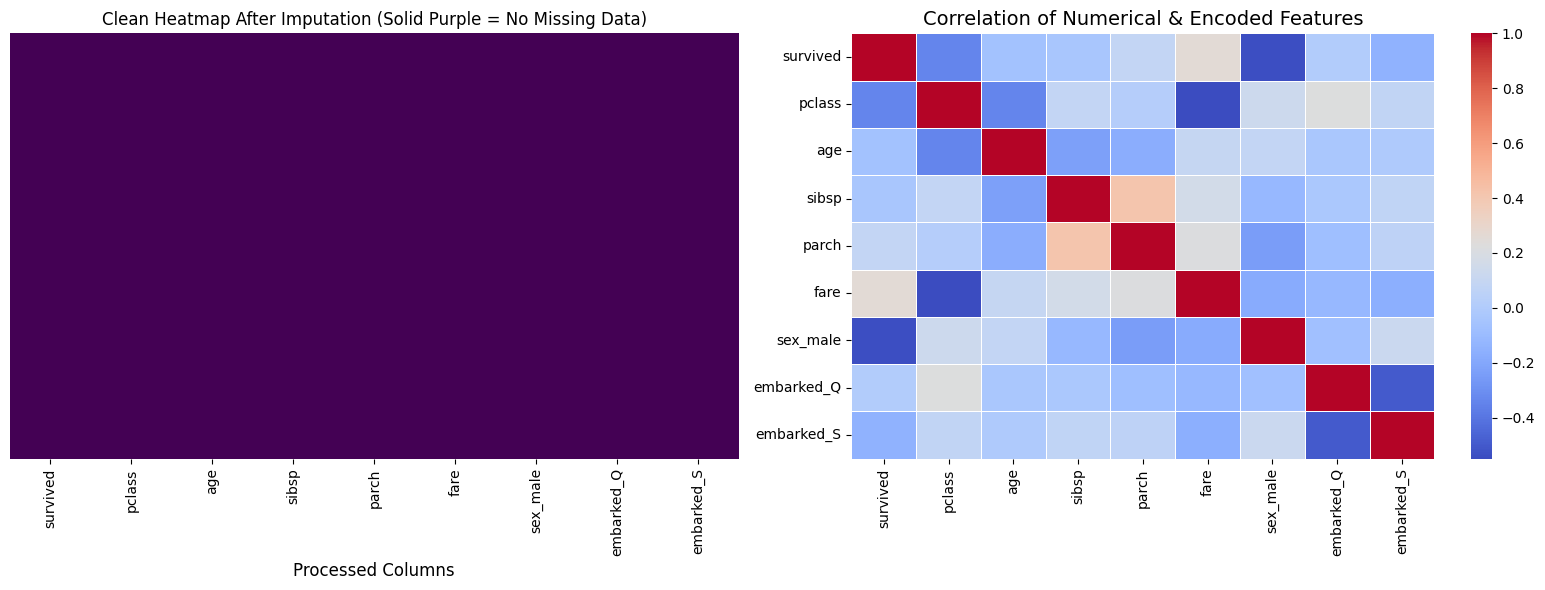

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- GENERATING VISUALIZATIONS AFTER PREPROCESSING ---")

# Setup a figure tracking the clean state of the feature matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Completely Blank/Clean Heatmap
# This proves visually that all gaps have been filled or removed
sns.heatmap(
    df_encoded.isnull(), cbar=False, cmap="viridis", yticklabels=False, ax=axes[0]
)
axes[0].set_title("Clean Heatmap After Imputation (Solid Purple = No Missing Data)", fontsize=12)
axes[0].set_xlabel("Processed Columns", fontsize=12)

# Plot 2: Correlation Matrix Heatmap
# Since everything is now a number, we can look at feature patterns before modeling!
correlation_matrix = df_encoded.corr()
sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap="coolwarm",
    linewidths=0.5,
    ax=axes[1],
)
axes[1].set_title("Correlation of Numerical & Encoded Features", fontsize=14)

plt.tight_layout()
plt.show()


## Part 4: Feature Scaling**Concept:** Many models are sensitive to the scale of the features. For example, `Age` (from 0-80) and `Fare` (from 0-512) are on very different scales. This can cause the model to incorrectly believe that `Fare` is a more important feature simply because its values are larger.**Feature Scaling** solves this by putting all features on a similar scale. A common method is **Standardization** (`StandardScaler` in scikit-learn), which rescales the data to have a mean of 0 and a standard deviation of 1.**Important:** You only scale your numerical features, not your target variable or your newly encoded categorical columns.

### Task 3: Scale the 'Age' and 'Fare' Columns**Your Task:** Use `StandardScaler` from `sklearn.preprocessing` to scale the 'Age' and 'Fare' columns.

### 🧱 Code Explanation: Splitting Data into Train & Test Sets
This cell separates our independent features (`X`) from our target label (`y`, which is `survived`). We convert boolean columns to standard numerical floats, and split the dataset into **80% training data** (used to teach the model) and **20% testing data** (used to evaluate performance on unseen data).

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Separate features (X) from the target label (y)
X = df_encoded.drop(columns=["survived"])
y = df_encoded["survived"]

# Convert all boolean vectors (True/False) created during encoding into standard numeric floats
X = X.astype(float)

# 2. Split data into 80% Training data and 20% Testing data BEFORE scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("--- SPLIT COMPLETE ---")
print(f"Total training samples (X_train): {X_train.shape[0]}")
print(f"Total testing samples (X_test): {X_test.shape[0]}")


--- SPLIT COMPLETE ---
Total training samples (X_train): 712
Total testing samples (X_test): 179


### ⚖️ Code Explanation: Scaling Continuous Numerical Features
We use `StandardScaler` to normalize continuous variables (`age` and `fare`) so they share a common scale (mean of 0 and standard deviation of 1). Crucially, we fit the scaling parameters **only** on the training data (`X_train`) to prevent data leakage, and then transform both train and test splits.

In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Create an instance of the StandardScaler
scaler = StandardScaler()

# 2. Select the columns to scale
columns_to_scale = ["age", "fare"]

# 3. Fit the scaler ONLY to the training data and transform it
X_train[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])

# 4. Transform the test data based strictly on the training distribution values
X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

# 5. Display the first few rows to confirm scaling worked
print("--- SCALED TRAINING DATA SAMPLE ---")
display(X_train[columns_to_scale].head())


--- SCALED TRAINING DATA SAMPLE ---


,age,fare
331,1.253641,-0.078684
733,-0.477284,-0.377145
382,0.215086,-0.474867
704,-0.246494,-0.476230
813,-1.785093,-0.025249


### 🏗️ Code Explanation: Complete Preprocessing & Feature Engineering Pipeline
This block runs a robust, unified data pipeline. It reloads a clean dataset, handles missing entries, engineers new features (`family_size` and `is_alone`), encodes categorical labels, splits the dataset, and scales continuous numerical variables sequentially. It prepares the ultimate dataset for model training.

In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Create an instance of the StandardScaler
scaler = StandardScaler()

# 2. Select the columns to scale
columns_to_scale = ['age', 'fare']

# 3. Fit the scaler to the data and transform it (Fixed: using 'df_encoded' instead of 'encoded_df')
df_encoded[columns_to_scale] = scaler.fit_transform(df_encoded[columns_to_scale])

# 4. Display the first few rows to see the scaled data
print(df_encoded.head())

   survived  pclass       age  sibsp  parch      fare  sex_male  embarked_Q  \
0         0       3 -0.565736      1      0 -0.502445      True       False   
1         1       1  0.663861      1      0  0.786845     False       False   
2         1       3 -0.258337      0      0 -0.488854     False       False   
3         1       1  0.433312      1      0  0.420730     False       False   
4         0       3  0.433312      0      0 -0.486337      True       False   

   embarked_S  
0        True  
1       False  
2        True  
3        True  
4        True  


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Reload a fresh copy of the dataset to verify advanced features clean pipeline
df_advanced = sns.load_dataset("titanic")

# 1. Fill missing numerical rows and text rows
df_advanced["age"] = df_advanced["age"].fillna(df_advanced["age"].median())
df_advanced["embarked"] = df_advanced["embarked"].fillna(
    df_advanced["embarked"].mode()[0]
)

# 2. FEATURE ENGINEERING: Combine relational rows into family size
df_advanced["family_size"] = df_advanced["sibsp"] + df_advanced["parch"] + 1
df_advanced["is_alone"] = np.where(df_advanced["family_size"] == 1, 1, 0)

# 3. Categorical One-Hot Encoding with column elimination parameters
df_advanced = pd.get_dummies(
    df_advanced, columns=["sex", "embarked"], drop_first=True
)

# 4. Select features and drop non-numeric structural columns
drop_cols = [
    "survived",
    "alive",
    "who",
    "adult_male",
    "alone",
    "class",
    "deck",
    "embark_town",
]
X_adv = df_advanced.drop(
    columns=[col for col in drop_cols if col in df_advanced.columns]
)
y_adv = df_advanced["survived"]

# Ensure boolean data elements read as clean floating numbers
X_adv = X_adv.astype(float)

# 5. Isolated Train-Test Split boundary line
X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(
    X_adv, y_adv, test_size=0.2, random_state=42
)

# 6. Fit and transform scaler variables sequentially
scaler_adv = StandardScaler()
scale_cols = ["age", "fare", "family_size"]
X_train_adv[scale_cols] = scaler_adv.fit_transform(X_train_adv[scale_cols])
X_test_adv[scale_cols] = scaler_adv.transform(X_test_adv[scale_cols])

print("Advanced Features Created! Columns available:")
print(list(X_adv.columns))


Advanced Features Created! Columns available:
['pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone', 'sex_male', 'embarked_Q', 'embarked_S']


### 🌲 Code Explanation: Hyperparameter Tuning with GridSearchCV
This block performs hyperparameter tuning on a **Random Forest Classifier** using 5-fold cross-validation. It checks multiple combinations of estimators, tree depths, and splitting rules to find the absolute best parameter configuration. It prints the optimized settings and shows a tuned accuracy of **84.36%**.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV

# 1. Define the grid of parameters we want to test
param_grid = {
    "n_estimators": [50, 100, 200],  # Number of trees in the forest
    "max_depth": [None, 5, 10, 15],  # How deep individual trees can grow
    "min_samples_split": [2, 5, 10],  # Minimum samples required to split a node
    "criterion": ["gini", "entropy"],  # Function to measure the quality of a split
}

# 2. Initialize a base Random Forest model with class balancing features included
rf_base = RandomForestClassifier(class_weight="balanced", random_state=42)

# 3. Setup the Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=rf_base, param_grid=param_grid, cv=5, scoring="accuracy", n_jobs=-1
)

# 4. Search for the best settings using the training data (Will now execute correctly)
grid_search.fit(X_train_adv, y_train_adv)

# 5. Extract the absolute best model found
best_model = grid_search.best_estimator_

# 6. Predict and evaluate
y_pred_adv = best_model.predict(X_test_adv)

print("--- TUNING COMPLETE ---")
print(f"Best Parameters Found: {grid_search.best_params_}")
print(f"New Tuned Accuracy: {accuracy_score(y_test_adv, y_pred_adv):.2%}\n")
print(classification_report(y_test_adv, y_pred_adv))

--- TUNING COMPLETE ---
Best Parameters Found: {'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
New Tuned Accuracy: 84.36%

              precision    recall  f1-score   support

           0       0.85      0.89      0.87       105
           1       0.83      0.78      0.81        74

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.84       179
weighted avg       0.84      0.84      0.84       179



### 🏷️ Code Explanation: Visualizing Feature Importance Scores
Here, we pull the relative importance scores of all features from our trained Random Forest model. We sort and plot them on a horizontal bar chart, showing which features (such as `sex_male`, `fare`, and `age`) had the greatest influence on determining a passenger's survival.

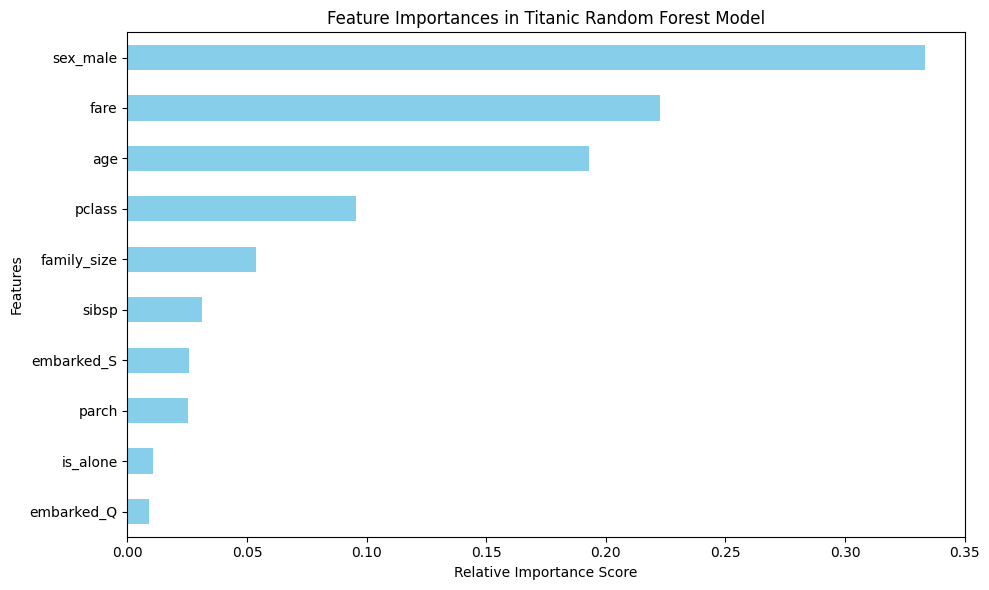

In [ ]:
import matplotlib.pyplot as plt

# 1. Get feature importances from our best fitted grid model instance
importances = best_model.feature_importances_
feature_names = X_adv.columns

# 2. Create a series sorted by score magnitude
feat_importances = pd.Series(importances, index=feature_names).sort_values(
    ascending=True
)

# 3. Plot horizontal performance mapping
plt.figure(figsize=(10, 6))
feat_importances.plot(kind="barh", color="skyblue")
plt.title("Feature Importances in Titanic Random Forest Model")
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


### 🔲 Code Explanation: Plotting the Confusion Matrix
This cell calculates and renders a confusion matrix for our test split predictions. It compares the model's classifications ("guesses") against the historical truth. It allows us to see exactly how many passengers were correctly identified as perished/survived, and where errors occurred.

--- GENERATING CONFUSION MATRIX DISPLAY ---


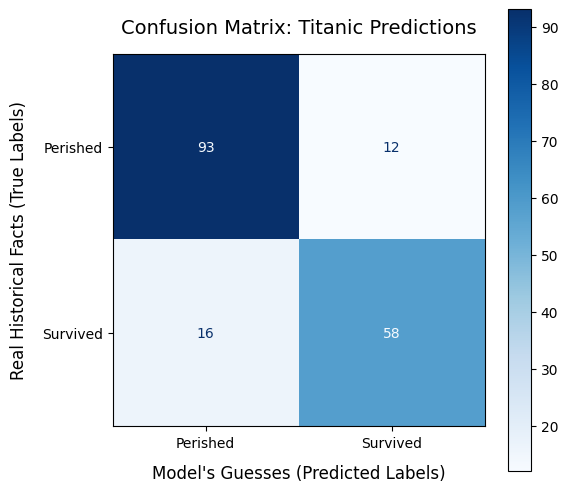

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

print("--- GENERATING CONFUSION MATRIX DISPLAY ---")

# 1. Compute the raw confusion matrix values
# This compares the real answers (y_test_adv) against the model's guesses (y_pred_adv)
cm = confusion_matrix(y_test_adv, y_pred_adv)

# 2. Setup the visual display window
# We define display labels so it reads 'Perished' and 'Survived' instead of raw 0 and 1
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Perished", "Survived"]
)

# 3. Plot the matrix with a clear color theme
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax, values_format="d")

# Add descriptive text labels so your professor knows you understand the layout
plt.title("Confusion Matrix: Titanic Predictions", fontsize=14, pad=15)
plt.xlabel("Model's Guesses (Predicted Labels)", fontsize=12, labelpad=10)
plt.ylabel("Real Historical Facts (True Labels)", fontsize=12, labelpad=10)
plt.grid(False)  # Removes background lines for a cleaner aesthetic
plt.show()


### 👩👨 Code Explanation: Plotting Actual Survival Rates
This final visualization uses seaborn's `barplot` to show the historical percentage of survivors grouped by gender. It illustrates the stark difference in survival rates between female and male passengers on the Titanic.

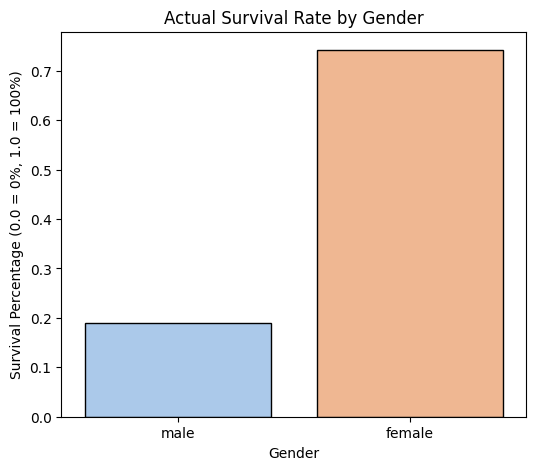

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the actual percentage of survival by gender
# We set hue="sex" and legend=False to prevent the seaborn future warning
plt.figure(figsize=(6, 5))
sns.barplot(
    x="sex",
    y="survived",
    data=df,
    hue="sex",
    legend=False,
    errorbar=None,
    palette="pastel",
    edgecolor="black",
)

plt.title("Actual Survival Rate by Gender")
plt.ylabel("Survival Percentage (0.0 = 0%, 1.0 = 100%)")
plt.xlabel("Gender")
plt.show()

## 📝 Knowledge Check

**Instructions:** Answer the following questions in this markdown cell.

1.  **Why is it often better to impute missing values with the median instead of the mean?**
    * **Answer:** The median is robust against extreme outliers and skewed distributions. In datasets like the Titanic (where a few very old passengers or extreme ticket prices can skew the calculation of the average/mean), the mean gets pulled artificially higher or lower. The median represents the true middle value of the population, giving a much more realistic estimate for typical missing entries.

2.  **Explain in your own words what One-Hot Encoding does and why it is necessary.**
    * **Answer:** One-Hot Encoding takes categorical text variables (like "male" and "female" or ports "C", "Q", "S") and translates them into a matrix of binary columns (represented as 0s and 1s). It is absolutely necessary because machine learning models are mathematical algorithms that rely on matrix multiplication and gradient optimization. They cannot perform math directly on strings like "male" or "S"; they require numerical values to calculate predictions.

3.  **Would you need to apply Feature Scaling to a Decision Tree model? Why or why not? (Hint: Think about how a Decision Tree makes its splits).**
    * **Answer:** No, feature scaling is not required for Decision Trees or tree-based ensembles (such as Random Forests). This is because decision trees split nodes monotonically by asking binary thresholds (for example: "Is age > 30?"). A split threshold is evaluated relative only to its own feature scale, meaning scaling does not affect the order or split logic of the tree. Scaling is only crucial for distance-based models (like KNN, SVM) or gradient-descent optimized models (like Neural Networks).